In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")


## load datsets

In [2]:
DATA_DIR = Path("../data/raw")

dataframes = {}

for year in range(2017, 2026):
    file_path = DATA_DIR / f"gpg_{year}.csv"

    df = pd.read_csv(file_path)

    dataframes[year] = df

    print(year, df.shape)

2017 (10569, 27)
2018 (10838, 27)
2019 (7055, 27)
2020 (10583, 27)
2021 (10567, 27)
2022 (10908, 27)
2023 (11169, 27)
2024 (11315, 27)
2025 (11201, 27)


##  combine datasets

In [3]:
all_data = []

for year, df in dataframes.items():
    df = df.copy()
    df["report_year"] = year
    all_data.append(df)

data = pd.concat(all_data, ignore_index=True)

print("Dataset shape:", data.shape)
data.head()

Dataset shape: (94205, 28)


,EmployerName,EmployerId,Address,PostCode,CompanyNumber,SicCodes,DiffMeanHourlyPercent,DiffMedianHourlyPercent,DiffMeanBonusPercent,DiffMedianBonusPercent,MaleBonusPercent,FemaleBonusPercent,MaleLowerQuartile,FemaleLowerQuartile,MaleLowerMiddleQuartile,FemaleLowerMiddleQuartile,MaleUpperMiddleQuartile,FemaleUpperMiddleQuartile,MaleTopQuartile,FemaleTopQuartile,CompanyLinkToGPGInfo,ResponsiblePerson,EmployerSize,CurrentName,SubmittedAfterTheDeadline,DueDate,DateSubmitted,report_year
0,"""Bryanston School"",Incorporated",676,"Bryanston House, Blandford, Dorset, DT11 0PX",DT11 0PX,00226143,85310,18.0,28.2,0.0,0.0,0.0,0.0,24.4,75.6,50.8,49.2,49.2,50.8,51.5,48.5,https://www.bryanston.co.uk/employment,Nick McRobb (Bursar and Clerk to the Governors),500 to 999,BRYANSTON SCHOOL,False,2018/04/05 00:00:00,2018/03/27 11:42:49,2017
1,"""RED BAND"" CHEMICAL COMPANY, LIMITED",16879,"19 Smith's Place, Leith Walk, Edinburgh, EH6 8NU",EH6 8NU,SC016876,47730,2.3,-2.7,15.0,37.5,15.6,66.7,20.3,79.7,25.4,74.6,10.3,89.7,18.1,81.9,NaN,Philip Galt (Managing Director),250 to 499,"""RED BAND"" CHEMICAL COMPANY, LIMITED",False,2018/04/05 00:00:00,2018/03/28 16:44:25,2017
2,118 LIMITED,681,"5th Floor, 1 Capital Quarter, Tyndall Street, ...",CF10 4BZ,03951948,61900,1.7,2.8,13.1,13.6,70.0,57.0,51.0,49.0,53.0,47.0,50.0,50.0,58.0,42.0,NaN,"Emma Crowe (VP, Human Resources)",500 to 999,118 LIMITED,False,2018/04/05 00:00:00,2018/03/27 19:10:41,2017
3,123 EMPLOYEES LTD,17677,"Alexandra Dock Business Centre, Fishermans Wha...",DN31 1UL,10530651,78300,41.0,36.0,-69.8,-157.2,50.0,73.5,0.0,100.0,2.0,98.0,11.0,89.0,23.0,77.0,NaN,Chloe Lines (Financial Controller),250 to 499,123 EMPLOYEES LTD,True,2018/04/05 00:00:00,2018/05/04 11:24:06,2017
4,1610 LIMITED,682,"Trinity Sports And Leisure, Chilton Street, Br...",TA6 3JA,06727055,93110,-22.0,-34.0,-47.0,-67.0,25.0,75.0,56.0,44.0,52.0,48.0,30.0,70.0,24.0,76.0,https://www.1610.org.uk/gender-pay-gap/,Tim Nightingale (CEO),250 to 499,1610 LIMITED,True,2018/04/05 00:00:00,2018/04/12 17:03:26,2017


## inspect data quality

In [4]:
print("Dataset information:")
data.info()

print("\nMissing values:")
print(data.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:")
print(data.duplicated().sum())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 94205 entries, 0 to 94204
Data columns (total 28 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   EmployerName               94205 non-null  str    
 1   EmployerId                 94205 non-null  int64  
 2   Address                    94047 non-null  str    
 3   PostCode                   93828 non-null  str    
 4   CompanyNumber              81767 non-null  str    
 5   SicCodes                   87687 non-null  str    
 6   DiffMeanHourlyPercent      94205 non-null  float64
 7   DiffMedianHourlyPercent    94205 non-null  float64
 8   DiffMeanBonusPercent       74284 non-null  float64
 9   DiffMedianBonusPercent     74282 non-null  float64
 10  MaleBonusPercent           94205 non-null  float64
 11  FemaleBonusPercent         94205 non-null  float64
 12  MaleLowerQuartile          93806 non-null  float64
 13  FemaleLowerQuartile        93806 non

## examine the median pay gap

In [5]:
data["DiffMedianHourlyPercent"] = pd.to_numeric(
    data["DiffMedianHourlyPercent"],
    errors="coerce"
)

print(data["DiffMedianHourlyPercent"].describe())

count    94205.000000
mean        11.815428
std         15.876093
min       -714.000000
25%          0.900000
50%          9.200000
75%         20.800000
max        121.200000
Name: DiffMedianHourlyPercent, dtype: float64


## plot the distribution

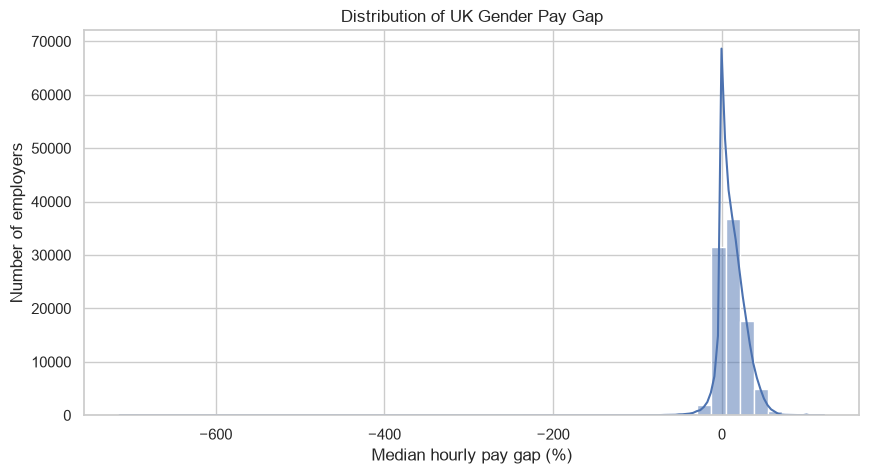

In [6]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data["DiffMedianHourlyPercent"].dropna(),
    bins=50,
    kde=True
)

plt.title("Distribution of UK Gender Pay Gap")
plt.xlabel("Median hourly pay gap (%)")
plt.ylabel("Number of employers")

plt.show()